# Validación computacional de resultados: duración de la titulación en el pregrado universitario chileno (2025)
Sumativa 2, Fase 3 · MCDI501 · Integrantes: Fernanda Ovalle Román, Sebastián Cajales Cid, César Lorca Bacián, Jorge Álvarez Ossandón.

Este notebook valida, mediante simulación y remuestreo, los resultados obtenidos en la Sumativa 1 (`S1/notebooks/Sumativa1_F2_Titulados.ipynb`): intervalos de confianza, pruebas de hipótesis y correlaciones. Usa la misma fuente de datos y la misma preparación.

Fuente: Titulados de Educación Superior 2025 (Mineduc). El archivo crudo debe estar en `data/raw/` en la raíz del repositorio.

## 1. Preparación de datos (replicada de la Sumativa 1)
Se repite exactamente la preparación de la S1 para trabajar sobre la misma base: carga del crudo, filtro a pregrado universitario, códigos de relleno (1900 y 0) convertidos a NaN sin imputar, variables derivadas (`semestres_reales`, `atraso_semestres`, `edad_titulacion`) y marcas de atípicos (Tukey) e inconsistencias. Los atípicos se conservan; en la sección de robustez se evalúa su efecto.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Raíz del repo: el notebook vive en S2/notebooks/, así que subimos dos niveles
RAIZ = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_CRUDO = RAIZ / "data" / "raw" / "20260817_Titulados_Ed_Superior_2025_WEB.csv"
RUTA_FIG = RAIZ / "S2" / "informe" / "figuras"
RUTA_RES = RAIZ / "S2" / "resultados"

crudo = pd.read_csv(RUTA_CRUDO, sep=";", encoding="utf-8", low_memory=False)
print(f"Filas: {crudo.shape[0]:,} | Columnas: {crudo.shape[1]}")

Filas: 328,998 | Columnas: 41


In [2]:
filtro = (crudo["nivel_global"] == "Pregrado") & (crudo["tipo_inst_1"] == "Universidades")
df = crudo.loc[filtro].copy()

# Códigos de relleno → NaN, con bandera, sin imputar
df["ingreso_sin_info"] = df["anio_ing_carr_ori"].eq(1900)
df["anio_ing_carr_ori"] = df["anio_ing_carr_ori"].replace(1900, np.nan)
df["sem_ing_carr_ori"]  = df["sem_ing_carr_ori"].replace(0, np.nan)

constantes = [col for col in df.columns if df[col].nunique(dropna=False) == 1]
df = df.drop(columns=constantes)

print(f"Pregrado U: {len(df):,} filas")
print(f"Sin info de ingreso: {df['ingreso_sin_info'].sum():,}")
print("Columnas constantes eliminadas:", constantes)

Pregrado U: 105,063 filas
Sin info de ingreso: 13,396
Columnas constantes eliminadas: ['cat_periodo', 'tipo_inst_1', 'nivel_global']


In [3]:
anio_tit = df["fecha_obtencion_titulo"] // 10000
mes_tit  = (df["fecha_obtencion_titulo"] // 100) % 100
sem_tit  = np.where(mes_tit <= 6, 1, 2)

# Semestres reales: del semestre de ingreso al de titulación, ambos incluidos
idx_ingreso = df["anio_ing_carr_ori"] * 2 + (df["sem_ing_carr_ori"] - 1)
idx_titulo  = anio_tit * 2 + (sem_tit - 1)
df["semestres_reales"] = idx_titulo - idx_ingreso + 1
df["atraso_semestres"] = df["semestres_reales"] - df["dur_total_carr"]

anio_nac = df["fec_nac_alu"] // 100
mes_nac  = df["fec_nac_alu"] % 100
df["edad_titulacion"] = ((anio_tit * 12 + mes_tit) - (anio_nac * 12 + mes_nac)) / 12

df["sexo"] = df["gen_alu"].map({1: "Hombre", 2: "Mujer"})
UMBRAL_ALTO = 4
df["atraso_alto"] = df["atraso_semestres"] > UMBRAL_ALTO

def marcar_atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    ric = q3 - q1
    return (serie < q1 - 1.5 * ric) | (serie > q3 + 1.5 * ric)

df["incons_antes_formal"] = df["semestres_reales"] < df["dur_total_carr"]
df["atipico_semestres"] = marcar_atipicos(df["semestres_reales"])
df["atipico_edad"]      = marcar_atipicos(df["edad_titulacion"])

print(df[["semestres_reales", "atraso_semestres", "edad_titulacion"]].agg(["count", "mean"]).round(3))
print(df[["incons_antes_formal", "atipico_semestres", "atipico_edad"]].sum())

       semestres_reales  atraso_semestres  edad_titulacion
count         91667.000         91667.000       105063.000
mean             12.986             3.398           27.966
incons_antes_formal     1511
atipico_semestres      13201
atipico_edad           10711
dtype: int64


## 2. Resultados de la Sumativa 1 a validar
Se registran los valores reportados en la S1 (secciones 2 a 4 de su notebook). Cada método de esta evaluación se compara contra ellos: IC *t* de la media (bootstrap), *t* de Welch y chi-cuadrado (permutación), correlaciones de Spearman (bootstrap) y parámetros de entrada para la simulación Monte Carlo.

In [4]:
# IC 95 % t para la media (S1, sección 3)
S1_IC_MEDIA = pd.DataFrame({
    "media":    [3.398, 12.986, 27.966],
    "IC95_inf": [3.367, 12.953, 27.927],
    "IC95_sup": [3.429, 13.019, 28.004],
}, index=["atraso_semestres", "semestres_reales", "edad_titulacion"])

# Prueba 1: atraso según sexo, t de Welch (S1, sección 4)
S1_WELCH = {"dif_medias": 1.068, "IC95_inf": 1.004, "IC95_sup": 1.132,
            "t": 32.76, "p": 1.09e-233, "d_cohen": 0.226,
            "media_h": 3.999, "sd_h": 5.434, "n_h": 40075,
            "media_m": 2.931, "sd_m": 4.101, "n_m": 51592}

# Prueba 2: jornada × atraso alto, chi-cuadrado (S1, sección 4)
S1_CHI2 = {"chi2": 316.09, "p": 1.03e-70, "V_cramer": 0.060,
           "pct_alto_diurna": 23.9, "pct_alto_vespertina": 32.9}

# Correlaciones de Spearman (S1, sección 2)
S1_SPEARMAN = pd.Series({
    ("semestres_reales", "atraso_semestres"): 0.82,
    ("atraso_semestres", "edad_titulacion"):  0.47,
    ("semestres_reales", "edad_titulacion"):  0.46,
    ("dur_total_carr",   "edad_titulacion"): -0.19,
    ("dur_total_carr",   "atraso_semestres"): 0.01,
}, name="rho_S1")

display(S1_IC_MEDIA)
display(pd.Series(S1_WELCH, name="Welch S1").to_frame().T)
display(pd.Series(S1_CHI2, name="Chi2 S1").to_frame().T)
display(S1_SPEARMAN.to_frame())

,media,IC95_inf,IC95_sup
atraso_semestres,3.398,3.367,3.429
semestres_reales,12.986,12.953,13.019
edad_titulacion,27.966,27.927,28.004


,dif_medias,IC95_inf,IC95_sup,t,p,d_cohen,media_h,sd_h,n_h,media_m,sd_m,n_m
Welch S1,1.068,1.004,1.132,32.76,1.090000e-233,0.226,3.999,5.434,40075.0,2.931,4.101,51592.0


,chi2,p,V_cramer,pct_alto_diurna,pct_alto_vespertina
Chi2 S1,316.09,1.030000e-70,0.06,23.9,32.9


rho_S1
semestres_reales atraso_semestres    0.82
atraso_semestres edad_titulacion     0.47
semestres_reales edad_titulacion     0.46
dur_total_carr   edad_titulacion    -0.19
                 atraso_semestres    0.01

In [5]:
# Verificación: recalcular IC t de la media y Welch con el df de esta S2
for v in S1_IC_MEDIA.index:
    x = df[v].dropna()
    ic = stats.t.interval(0.95, df=len(x) - 1, loc=x.mean(), scale=stats.sem(x))
    print(f"{v:18s} media={x.mean():.3f}  IC95=[{ic[0]:.3f}; {ic[1]:.3f}]")

h = df.loc[df["sexo"] == "Hombre", "atraso_semestres"].dropna()
m = df.loc[df["sexo"] == "Mujer",  "atraso_semestres"].dropna()
welch = stats.ttest_ind(h, m, equal_var=False)
print(f"\nWelch: dif={h.mean() - m.mean():.3f}  t={welch.statistic:.2f}  p={welch.pvalue:.2e}")

atraso_semestres   media=3.398  IC95=[3.367; 3.429]
semestres_reales   media=12.986  IC95=[12.953; 13.019]
edad_titulacion    media=27.966  IC95=[27.927; 28.004]

Welch: dif=1.068  t=32.76  p=1.09e-233


## 3. Validación de intervalos de confianza mediante bootstrap
En la S1 se estimaron IC 95 % *t* para la media, que suponen normalidad aproximada del promedio (Teorema Central del Límite). Aquí se validan con **bootstrap no paramétrico**: se remuestrea con reemplazo la muestra observada B = 10.000 veces, se recalcula el estadístico en cada remuestra y la distribución de esas réplicas aproxima la distribución muestral del estimador, sin suponer una forma.

Se comparan dos intervalos bootstrap:
- **Percentil**: percentiles 2,5 y 97,5 de las réplicas.
- **BCa** (*bias-corrected and accelerated*): ajusta los percentiles por el sesgo de las réplicas (*z₀*) y por la asimetría del estimador (aceleración *a*, estimada con jackknife).

Parámetros validados: media de `atraso_semestres`, media de `edad_titulacion` y diferencia de medias de atraso entre hombres y mujeres (IC de Welch de la S1).

In [6]:
B = 10_000                          # número de remuestras (mínimo exigido)
rng = np.random.default_rng(42)     # semilla fija, igual que en la S1

def boot_media(x, B=B, bloque=100):
    """Réplicas bootstrap de la media: B remuestras con reemplazo de tamaño n.
    Se generan de a 100 para no saturar la memoria."""
    n = len(x)
    reps = np.empty(B)
    for i in range(0, B, bloque):
        idx = rng.integers(0, n, size=(min(bloque, B - i), n))
        reps[i:i + bloque] = x[idx].mean(axis=1)
    return reps

def jack_media(x):
    """Medias jackknife: la media dejando fuera cada observación, una a la vez."""
    return (x.sum() - x) / (len(x) - 1)

def ic_percentil(reps, conf=0.95):
    alfa = 1 - conf
    return np.percentile(reps, [100 * alfa / 2, 100 * (1 - alfa / 2)])

def ic_bca(reps, theta, jack, conf=0.95):
    """IC BCa: corrige los percentiles por sesgo (z0) y asimetría (a)."""
    alfa = 1 - conf
    z0 = stats.norm.ppf((reps < theta).mean())           # sesgo de las réplicas
    d = jack.mean() - jack
    a = (d ** 3).sum() / (6 * ((d ** 2).sum()) ** 1.5)   # aceleración (jackknife)
    z = stats.norm.ppf([alfa / 2, 1 - alfa / 2])
    p = stats.norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))
    return np.percentile(reps, 100 * p), z0, a

In [7]:
x_atraso = df["atraso_semestres"].dropna().to_numpy()
x_edad   = df["edad_titulacion"].dropna().to_numpy()
h = df.loc[df["sexo"] == "Hombre", "atraso_semestres"].dropna().to_numpy()
m = df.loc[df["sexo"] == "Mujer",  "atraso_semestres"].dropna().to_numpy()

# Diferencia de medias: se remuestrea cada grupo por separado (bootstrap estratificado)
boot = {
    "media atraso": (x_atraso.mean(), boot_media(x_atraso), jack_media(x_atraso)),
    "media edad":   (x_edad.mean(),   boot_media(x_edad),   jack_media(x_edad)),
    "dif. atraso H−M": (h.mean() - m.mean(),
                        boot_media(h) - boot_media(m),
                        np.concatenate([jack_media(h) - m.mean(), h.mean() - jack_media(m)])),
}

ic_s1 = {
    "media atraso":    (S1_IC_MEDIA.loc["atraso_semestres", "IC95_inf"], S1_IC_MEDIA.loc["atraso_semestres", "IC95_sup"]),
    "media edad":      (S1_IC_MEDIA.loc["edad_titulacion", "IC95_inf"],  S1_IC_MEDIA.loc["edad_titulacion", "IC95_sup"]),
    "dif. atraso H−M": (S1_WELCH["IC95_inf"], S1_WELCH["IC95_sup"]),
}

filas = []
for nombre, (theta, reps, jack) in boot.items():
    perc = ic_percentil(reps)
    bca, z0, a = ic_bca(reps, theta, jack)
    t_inf, t_sup = ic_s1[nombre]
    filas.append({"parámetro": nombre, "estimado": theta,
                  "IC t S1": f"[{t_inf:.3f}; {t_sup:.3f}]",
                  "IC percentil": f"[{perc[0]:.3f}; {perc[1]:.3f}]",
                  "IC BCa": f"[{bca[0]:.3f}; {bca[1]:.3f}]",
                  "ancho t": t_sup - t_inf, "ancho perc": perc[1] - perc[0], "ancho BCa": bca[1] - bca[0],
                  "EE boot": reps.std(ddof=1), "z0": z0, "a": a})

tabla_boot = pd.DataFrame(filas).set_index("parámetro")
tabla_boot.round(4)

,estimado,IC t S1,IC percentil,IC BCa,ancho t,ancho perc,ancho BCa,EE boot,z0,a
parámetro,,,,,,,,,,
media atraso,3.3980,[3.367; 3.429],[3.367; 3.429],[3.367; 3.429],0.062,0.0614,0.0615,0.0158,-0.0013,0.0024
media edad,27.9656,[27.927; 28.004],[27.927; 28.005],[27.927; 28.005],0.077,0.0784,0.0784,0.0200,0.0045,0.0011
dif. atraso H−M,1.0680,[1.004; 1.132],[1.005; 1.132],[1.006; 1.133],0.128,0.1269,0.1268,0.0324,0.0030,0.0015


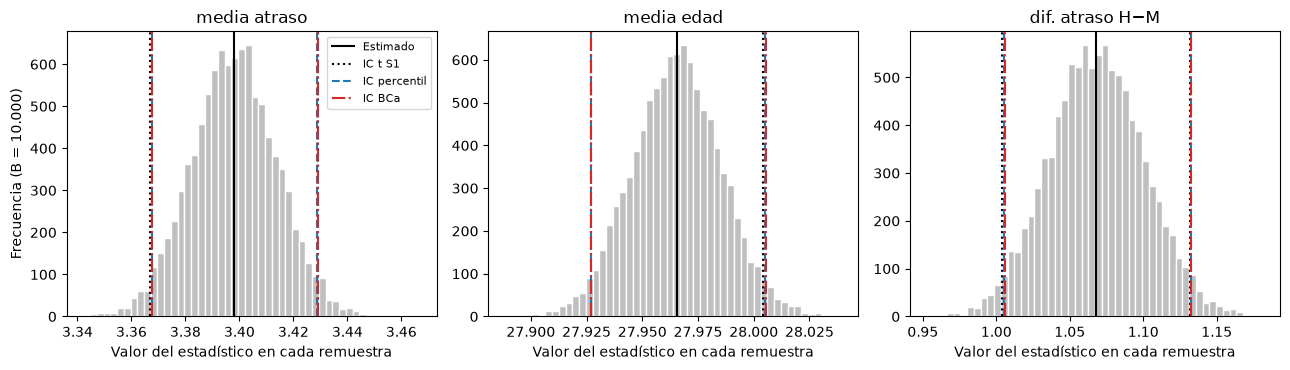

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8))

for ax, (nombre, (theta, reps, jack)) in zip(ejes, boot.items()):
    perc = ic_percentil(reps)
    bca, _, _ = ic_bca(reps, theta, jack)
    t_inf, t_sup = ic_s1[nombre]

    ax.hist(reps, bins=50, color="0.75", edgecolor="white")
    ax.axvline(theta, color="black", linewidth=1.5, label="Estimado")
    for v in (t_inf, t_sup):
        ax.axvline(v, color="black", linestyle=":", label="IC t S1" if v == t_inf else None)
    for v in perc:
        ax.axvline(v, color="tab:blue", linestyle="--", label="IC percentil" if v == perc[0] else None)
    for v in bca:
        ax.axvline(v, color="tab:red", linestyle="-.", label="IC BCa" if v == bca[0] else None)
    ax.set_title(nombre)
    ax.set_xlabel("Valor del estadístico en cada remuestra")

ejes[0].set_ylabel("Frecuencia (B = 10.000)")
ejes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIG / "fig_bootstrap_ic.png", dpi=300)
plt.show()

### Análisis de la validación bootstrap
**Concordancia.** Para los tres parámetros los IC percentil y BCa coinciden con los IC clásicos de la S1 hasta el tercer decimal (diferencias de ancho < 0,002). La media de atraso (3,398; IC *t* [3,367; 3,429]) se reproduce exactamente; en edad y en la diferencia H−M los límites difieren a lo más en 0,001. El error estándar bootstrap (0,016; 0,020; 0,032) es prácticamente igual al error estándar analítico de la S1.

**Por qué coinciden pese a la asimetría.** `atraso_semestres` es muy asimétrica (asimetría 4,41 en la S1) y no es normal; sin embargo, el IC *t* no supone normalidad de los datos sino de la **media muestral**. Con n = 91.667 el Teorema Central del Límite se cumple holgadamente: las distribuciones bootstrap son simétricas y acampanadas, la corrección de sesgo *z₀* ≈ 0 y la aceleración *a* ≈ 0,002. Por eso BCa no corrige casi nada respecto del percentil.

**Supuestos y confiabilidad.** El IC *t* supone normalidad aproximada del estimador e independencia; el bootstrap supone que la muestra representa a la población e independencia entre observaciones. La independencia se cumple casi totalmente: solo 461 personas (0,88 % de las filas) tienen más de un título. Con este tamaño muestral los tres métodos son igualmente confiables para la media; BCa sería preferible en muestras pequeñas o con estimadores sesgados, donde *z₀* y *a* se alejan de 0.

**Limitación del bootstrap con datos discretos.** En la S1 el IC bootstrap de la mediana de atraso fue [2; 2]: la variable es entera y casi todas las remuestras tienen la misma mediana. No es un error sino una propiedad de los datos, y es la razón por la que aquí se valida la media y no la mediana.

**Conclusión.** Los IC de la S1 quedan **validados**: son robustos al método de estimación.

## 4. Validación de pruebas de hipótesis mediante permutación
Un test de permutación no supone normalidad ni varianzas iguales: solo supone que, **si H0 es cierta, las etiquetas de grupo son intercambiables**. Se mantiene fijo el estadístico (diferencia entre grupos), se reasignan al azar las etiquetas B = 10.000 veces y se obtiene la distribución del estadístico bajo H0. El valor *p* de permutación es la proporción de permutaciones con un estadístico al menos tan extremo como el observado (bilateral), con la corrección (conteo + 1)/(B + 1).

Se validan las dos pruebas de la S1:
- **Prueba 1** (*t* de Welch): diferencia de medias de atraso entre hombres y mujeres.
- **Prueba 2** (chi-cuadrado 2×2): diferencia en el % de atraso alto (> 4 semestres) entre jornada vespertina y diurna. En una tabla 2×2 el chi-cuadrado equivale a contrastar esta diferencia de proporciones.

In [9]:
def test_permutacion(valores, en_grupo_a, B=B):
    """Test de permutación de dos grupos. Estadístico: media del grupo A − media del grupo B.
    Bajo H0 las etiquetas son intercambiables: se reasignan al azar B veces."""
    n, n_a = len(valores), en_grupo_a.sum()
    obs = valores[en_grupo_a].mean() - valores[~en_grupo_a].mean()
    total = valores.sum()
    dist = np.empty(B)
    for b in range(B):
        s_a = valores[rng.permutation(n)[:n_a]].sum()      # n_a valores al azar forman el "grupo A"
        dist[b] = s_a / n_a - (total - s_a) / (n - n_a)
    p = (np.sum(np.abs(dist) >= abs(obs)) + 1) / (B + 1)  # bilateral, con corrección +1
    return obs, dist, p

# Prueba 1: atraso según sexo
sub1 = df[df["atraso_semestres"].notna()]
obs1, dist1, p1 = test_permutacion(sub1["atraso_semestres"].to_numpy(),
                                   (sub1["sexo"] == "Hombre").to_numpy())

# Prueba 2: % de atraso alto, vespertina vs diurna (en puntos porcentuales)
sub2 = df[df["jornada"].isin(["Diurna", "Vespertina"]) & df["atraso_semestres"].notna()]
obs2, dist2, p2 = test_permutacion(100 * sub2["atraso_alto"].to_numpy(dtype=float),
                                   (sub2["jornada"] == "Vespertina").to_numpy())

tabla_perm = pd.DataFrame({
    "estadístico observado": [obs1, obs2],
    "máx |permutado|":       [np.abs(dist1).max(), np.abs(dist2).max()],
    "obs / DE permutación":  [obs1 / dist1.std(), obs2 / dist2.std()],
    "p paramétrico S1":      [S1_WELCH["p"], S1_CHI2["p"]],
    "p permutación":         [p1, p2],
    "p mínimo posible":      [1 / (B + 1)] * 2,
}, index=["Welch: atraso H − M (semestres)", "Chi²: % atraso alto Vesp − Diur (pp)"])
tabla_perm

,estadístico observado,máx |permutado|,obs / DE permutación,p paramétrico S1,p permutación,p mínimo posible
Welch: atraso H − M (semestres),1.068033,0.120262,33.769191,1.090000e-233,0.0001,0.0001
Chi²: % atraso alto Vesp − Diur (pp),9.062693,1.984751,17.587504,1.030000e-70,0.0001,0.0001


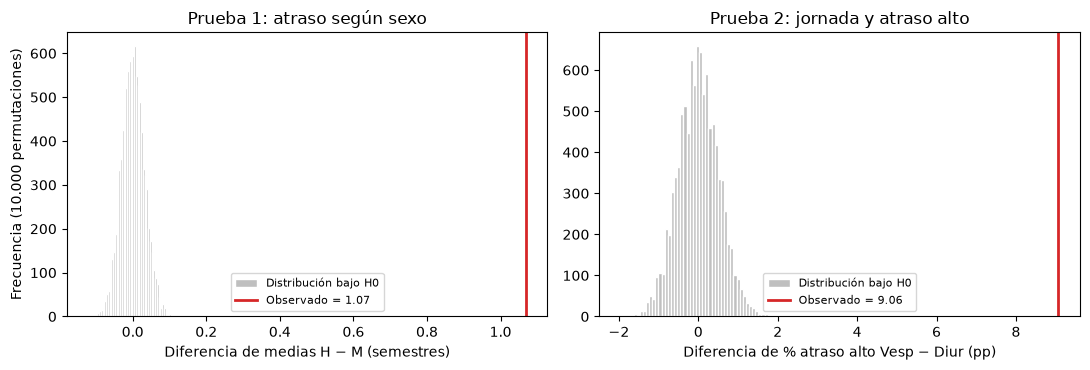

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
paneles = [
    (ejes[0], dist1, obs1, "Prueba 1: atraso según sexo", "Diferencia de medias H − M (semestres)"),
    (ejes[1], dist2, obs2, "Prueba 2: jornada y atraso alto", "Diferencia de % atraso alto Vesp − Diur (pp)"),
]
for ax, dist, obs, titulo, xlab in paneles:
    ax.hist(dist, bins=50, color="0.75", edgecolor="white", label="Distribución bajo H0")
    ax.axvline(obs, color="tab:red", linewidth=2, label=f"Observado = {obs:.2f}")
    ax.set_title(titulo)
    ax.set_xlabel(xlab)
    ax.legend(fontsize=8)

ejes[0].set_ylabel("Frecuencia (10.000 permutaciones)")
fig.tight_layout()
fig.savefig(RUTA_FIG / "fig_permutacion.png", dpi=300)
plt.show()

### Análisis de la validación por permutación
**Concordancia.** Ambas pruebas de la S1 se confirman. En la prueba 1 la diferencia observada (1,068 semestres) es casi nueve veces mayor que la máxima obtenida en 10.000 permutaciones (0,120); en la prueba 2 la diferencia de 9,06 pp supera ampliamente el máximo permutado (1,98 pp). En ningún caso una permutación alcanzó el valor observado, por lo que *p* = 1/(B + 1) ≈ 0,0001 en ambas.

**Por qué los *p* difieren en magnitud sin contradecirse.** El *p* paramétrico de la S1 (1,1·10⁻²³³ y 1,0·10⁻⁷⁰) proviene de una distribución teórica y puede ser arbitrariamente pequeño; el *p* de permutación tiene un piso de 1/(B + 1), así que solo puede informarse como *p* < 0,0001. Ambos llevan a la misma decisión (rechazar H0 con α = 0,05). La concordancia es también cuantitativa: el estadístico observado está a 33,8 desviaciones estándar de la distribución de permutación (*t* de Welch = 32,76) en la prueba 1, y a 17,6 en la prueba 2 (√χ² = √316,09 = 17,8).

**Supuestos y método más apropiado.** Welch supone normalidad aproximada de las medias (garantizada por el TCL con n ≈ 40.000 y 51.000 por grupo) y admite varianzas distintas, lo que es necesario aquí porque Levene las rechazó en la S1. La permutación no supone ninguna distribución, pero su H0 es más estricta (distribuciones idénticas): con varianzas distintas no aísla solo la diferencia de medias. Para este caso, Welch es la prueba principal adecuada y la permutación es una confirmación libre de supuestos distribucionales. Con muestras pequeñas o datos muy asimétricos la permutación ganaría relevancia.

**Significancia no es magnitud.** Con n tan grande cualquier diferencia real resulta significativa. Ambos efectos son pequeños (d de Cohen = 0,23; V de Cramér = 0,06): la conclusión robusta es que **hay** diferencias por sexo y jornada, no que sean grandes.

## 5. Estabilidad de correlaciones mediante bootstrap
Se evalúa si las correlaciones de Spearman reportadas en la S1 son estables frente al remuestreo. Para cada par se generan B = 10.000 remuestras **de filas completas** (se conserva el emparejamiento de las dos variables), se recalcula ρ en cada una y se obtiene su IC 95 % percentil.

Criterio: una correlación es **robusta** si su IC no incluye 0 y es estrecho; es **inestable o nula** si el IC incluye 0 o es ancho. Se analizan cuatro pares: atraso–edad, semestres reales–edad, duración formal–edad y duración formal–atraso. Se excluye semestres reales–atraso (ρ = 0,82) porque el atraso se define como semestres reales − duración formal: esa correlación es por construcción y no aporta información.

Como todas las variables son discretas (semestres enteros y edad en meses), los rangos de cada remuestra se calculan por conteo de valores, lo que da exactamente el mismo ρ que `scipy.stats.spearmanr` en una fracción del tiempo.

In [11]:
def rangos_promedio(codigos, k):
    """Rangos promedio (con empates) a partir del código de cada valor único."""
    conteo = np.bincount(codigos, minlength=k)
    antes = np.cumsum(conteo) - conteo          # cuántos valores son menores
    return (antes + (conteo + 1) / 2)[codigos]

def spearman_boot(x, y, B=B):
    """Réplicas bootstrap de rho de Spearman remuestreando pares (x, y) completos."""
    _, cx = np.unique(x, return_inverse=True)
    _, cy = np.unique(y, return_inverse=True)
    kx, ky, n = cx.max() + 1, cy.max() + 1, len(x)
    reps = np.empty(B)
    for b in range(B):
        i = rng.integers(0, n, n)
        reps[b] = np.corrcoef(rangos_promedio(cx[i], kx), rangos_promedio(cy[i], ky))[0, 1]
    return reps

def fuerza(r):
    r = abs(r)
    return "despreciable" if r < 0.1 else "débil" if r < 0.3 else "moderada" if r < 0.5 else "fuerte"

PARES = [("atraso_semestres", "edad_titulacion"),
         ("semestres_reales", "edad_titulacion"),
         ("dur_total_carr",   "edad_titulacion"),
         ("dur_total_carr",   "atraso_semestres")]

boot_corr, filas = {}, []
for v1, v2 in PARES:
    datos = df[[v1, v2]].dropna()
    x, y = datos[v1].to_numpy(), datos[v2].to_numpy()
    rho = stats.spearmanr(x, y).statistic
    reps = spearman_boot(x, y)
    li, ls = ic_percentil(reps)
    nombre = f"{v1} – {v2}"
    boot_corr[nombre] = reps
    incluye_0 = li <= 0 <= ls
    filas.append({"par": nombre, "n": len(datos), "rho S1": S1_SPEARMAN[(v1, v2)], "rho": rho,
                  "IC95 inf": li, "IC95 sup": ls, "ancho": ls - li, "EE boot": reps.std(ddof=1),
                  "incluye 0": incluye_0,
                  "estabilidad": "nula / inestable" if incluye_0 or (ls - li) > 0.1 else "robusta",
                  "fuerza": fuerza(rho)})

tabla_corr = pd.DataFrame(filas).set_index("par")
tabla_corr.round(4)

,n,rho S1,rho,IC95 inf,IC95 sup,ancho,EE boot,incluye 0,estabilidad,fuerza
par,,,,,,,,,,
atraso_semestres – edad_titulacion,91667,0.47,0.4661,0.4602,0.4719,0.0117,0.0030,False,robusta,moderada
semestres_reales – edad_titulacion,91667,0.46,0.4609,0.4541,0.4679,0.0138,0.0035,False,robusta,moderada
dur_total_carr – edad_titulacion,105063,-0.19,-0.1890,-0.1955,-0.1827,0.0129,0.0033,False,robusta,débil
dur_total_carr – atraso_semestres,91667,0.01,0.0089,0.0022,0.0156,0.0135,0.0034,False,robusta,despreciable


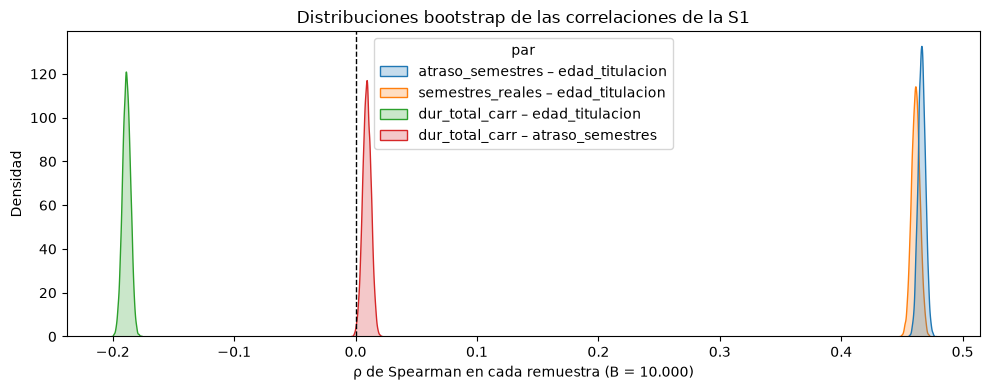

In [12]:
import seaborn as sns

largo = pd.DataFrame({"par": np.repeat(list(boot_corr), B),
                      "rho": np.concatenate(list(boot_corr.values()))})

fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(data=largo, x="rho", hue="par", fill=True, common_norm=False, ax=ax)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("ρ de Spearman en cada remuestra (B = 10.000)")
ax.set_ylabel("Densidad")
ax.set_title("Distribuciones bootstrap de las correlaciones de la S1")
fig.tight_layout()
fig.savefig(RUTA_FIG / "fig_bootstrap_correlaciones.png", dpi=300)
plt.show()

### Análisis de estabilidad de las correlaciones
**Reproducción y estabilidad.** Las cuatro correlaciones reproducen los valores de la S1 (diferencias < 0,005, atribuibles al redondeo a dos decimales en la S1). Sus distribuciones bootstrap son simétricas y muy concentradas: error estándar ≈ 0,003 e IC 95 % de ancho entre 0,012 y 0,014. Ningún IC incluye el 0, por lo que, según el criterio definido, **las cuatro son estables frente al remuestreo**.

**Estable no significa relevante.** Con n ≈ 92.000–105.000 el bootstrap estima el ρ con gran precisión, de modo que incluso asociaciones mínimas resultan distintas de 0. Por eso se clasifican también por fuerza:
- **atraso–edad (ρ = 0,47; IC [0,460; 0,472])** y **semestres reales–edad (ρ = 0,46; IC [0,454; 0,468])**: moderadas y robustas. Parte de esta relación es esperable: cada semestre adicional de permanencia suma medio año a la edad de titulación.
- **duración formal–edad (ρ = −0,19; IC [−0,196; −0,183])**: débil pero robusta. Las carreras más largas se asocian a titulados algo más jóvenes; una explicación posible (no verificada aquí) es que las carreras cortas concentran más ingreso tardío o programas para trabajadores.
- **duración formal–atraso (ρ = 0,009; IC [0,002; 0,016])**: el IC excluye el 0 por muy poco, pero el valor es **despreciable**. En la práctica el atraso no depende de la duración formal de la carrera: las carreras largas no acumulan más semestres de atraso que las cortas.

**Limitación.** El bootstrap mide la variabilidad muestral, no la heterogeneidad entre subgrupos. Una correlación estable en el total podría cambiar por área o tipo de institución; eso se aborda en el análisis de robustez.

## 6. Simulación Monte Carlo: ¿qué observaría una sola cohorte?
**Escenario.** La S1 detectó que los hombres se atrasan 1,07 semestres más que las mujeres usando 91.667 titulados. Sin embargo, una universidad o carrera que analiza su propia cohorte trabaja con decenas o cientos de casos. Se simula qué observaría esa institución: cuánto varía, solo por azar, el atraso de una cohorte a otra, y con qué probabilidad (potencia) una prueba de Welch detectaría la diferencia por sexo según el tamaño de la cohorte (n = 50, 100, 200, 500 y 1.000).

**Modelo (solo parámetros de la S1).**
- Sexo de cada titulado ~ Bernoulli con P(mujer) = 51.592 / 91.667 = 0,563.
- Atraso según sexo ~ **binomial negativa**, ajustada por método de momentos a la media y desviación estándar de cada grupo en la S1 (hombres: 3,999 y 5,434; mujeres: 2,931 y 4,101). Se elige porque el atraso es un conteo discreto, asimétrico y con varianza mucho mayor que la media (sobredispersión), lo que descarta la normal y la Poisson.
- Atraso alto: más de 4 semestres, igual que en la S1.

Para cada tamaño se simulan R = 10.000 cohortes independientes.

In [13]:
P_MUJER = S1_WELCH["n_m"] / (S1_WELCH["n_h"] + S1_WELCH["n_m"])

def params_nb(media, de):
    """Binomial negativa por método de momentos: media = r(1-p)/p y var = r(1-p)/p²."""
    r = media ** 2 / (de ** 2 - media)
    p = r / (r + media)
    return r, p

NB_H = params_nb(S1_WELCH["media_h"], S1_WELCH["sd_h"])
NB_M = params_nb(S1_WELCH["media_m"], S1_WELCH["sd_m"])

# Comparación modelo vs datos observados (h y m vienen de la sección 3)
chequeo = pd.DataFrame({
    "media modelo":       [stats.nbinom(*NB_H).mean(), stats.nbinom(*NB_M).mean()],
    "media observada":    [h.mean(), m.mean()],
    "DE modelo":          [stats.nbinom(*NB_H).std(), stats.nbinom(*NB_M).std()],
    "DE observada":       [h.std(ddof=1), m.std(ddof=1)],
    "% alto modelo":      [100 * stats.nbinom(*NB_H).sf(UMBRAL_ALTO), 100 * stats.nbinom(*NB_M).sf(UMBRAL_ALTO)],
    "% alto observado":   [100 * (h > UMBRAL_ALTO).mean(), 100 * (m > UMBRAL_ALTO).mean()],
    "% negativos obs.":   [100 * (h < 0).mean(), 100 * (m < 0).mean()],
}, index=["Hombres", "Mujeres"])

print(f"P(mujer) = {P_MUJER:.4f}")
print(f"BN hombres: r = {NB_H[0]:.4f}, p = {NB_H[1]:.4f}")
print(f"BN mujeres: r = {NB_M[0]:.4f}, p = {NB_M[1]:.4f}")
chequeo.round(3)

P(mujer) = 0.5628
BN hombres: r = 0.6264, p = 0.1354
BN mujeres: r = 0.6186, p = 0.1743


,media modelo,media observada,DE modelo,DE observada,% alto modelo,% alto observado,% negativos obs.
Hombres,3.999,3.999,5.434,5.434,30.361,29.707,2.001
Mujeres,2.931,2.931,4.101,4.101,22.566,20.526,1.374


In [14]:
R = 10_000                         # iteraciones Monte Carlo por tamaño
TAMANOS = [50, 100, 200, 500, 1000]
ALFA = 0.05

def simular_cohortes(n, R=R):
    """R cohortes de n titulados: sexo ~ Bernoulli(P_MUJER), atraso ~ BN según sexo (parámetros S1).
    Devuelve, por cohorte: media de atraso, % atraso alto, diferencia H − M y si Welch rechaza H0."""
    mujer = rng.random((R, n)) < P_MUJER
    atraso = np.where(mujer, rng.negative_binomial(*NB_M, size=(R, n)),
                             rng.negative_binomial(*NB_H, size=(R, n))).astype(float)
    n_m = mujer.sum(axis=1)
    n_h = n - n_m
    # Sumas y sumas de cuadrados por grupo, cohorte a cohorte
    s_m = np.where(mujer, atraso, 0).sum(axis=1);       s_h = atraso.sum(axis=1) - s_m
    q_m = np.where(mujer, atraso ** 2, 0).sum(axis=1);  q_h = (atraso ** 2).sum(axis=1) - q_m
    m_m, m_h = s_m / n_m, s_h / n_h
    v_m = (q_m - n_m * m_m ** 2) / (n_m - 1)
    v_h = (q_h - n_h * m_h ** 2) / (n_h - 1)
    # t de Welch con grados de libertad de Welch-Satterthwaite
    ee2_h, ee2_m = v_h / n_h, v_m / n_m
    t = (m_h - m_m) / np.sqrt(ee2_h + ee2_m)
    gl = (ee2_h + ee2_m) ** 2 / (ee2_h ** 2 / (n_h - 1) + ee2_m ** 2 / (n_m - 1))
    p = 2 * stats.t.sf(np.abs(t), gl)
    return pd.DataFrame({"media_atraso": atraso.mean(axis=1),
                         "pct_alto": 100 * (atraso > UMBRAL_ALTO).mean(axis=1),
                         "dif_HM": m_h - m_m,
                         "rechaza": p < ALFA})

sims = {n: simular_cohortes(n) for n in TAMANOS}
print({n: s.shape for n, s in sims.items()})

{50: (10000, 4), 100: (10000, 4), 200: (10000, 4), 500: (10000, 4), 1000: (10000, 4)}


In [15]:
filas = []
for n, s in sims.items():
    pot = s["rechaza"].mean()
    filas.append({
        "n cohorte": n,
        "media atraso": s["media_atraso"].mean(),
        "rango 95% media": f"[{s['media_atraso'].quantile(0.025):.2f}; {s['media_atraso'].quantile(0.975):.2f}]",
        "% alto": s["pct_alto"].mean(),
        "rango 95% % alto": f"[{s['pct_alto'].quantile(0.025):.1f}; {s['pct_alto'].quantile(0.975):.1f}]",
        "dif H−M": s["dif_HM"].mean(),
        "rango 95% dif": f"[{s['dif_HM'].quantile(0.025):.2f}; {s['dif_HM'].quantile(0.975):.2f}]",
        "% cohortes con dif < 0": 100 * (s["dif_HM"] < 0).mean(),
        "potencia Welch %": 100 * pot,
        "EE Monte Carlo potencia": 100 * np.sqrt(pot * (1 - pot) / R),
    })

tabla_mc = pd.DataFrame(filas).set_index("n cohorte")
tabla_mc.round(2)

,media atraso,rango 95% media,% alto,rango 95% % alto,dif H−M,rango 95% dif,% cohortes con dif < 0,potencia Welch %,EE Monte Carlo potencia
n cohorte,,,,,,,,,
50,3.38,[2.20; 4.84],25.91,[14.0; 38.0],1.04,[-1.60; 4.00],23.18,8.54,0.28
100,3.40,[2.54; 4.41],26.02,[18.0; 35.0],1.08,[-0.81; 3.12],13.70,16.45,0.37
200,3.40,[2.75; 4.11],26.00,[20.0; 32.5],1.06,[-0.26; 2.48],5.90,31.01,0.46
500,3.40,[2.99; 3.82],25.98,[22.2; 29.8],1.06,[0.21; 1.94],0.74,67.68,0.47
1000,3.40,[3.10; 3.70],25.99,[23.2; 28.7],1.07,[0.47; 1.69],0.03,94.05,0.24


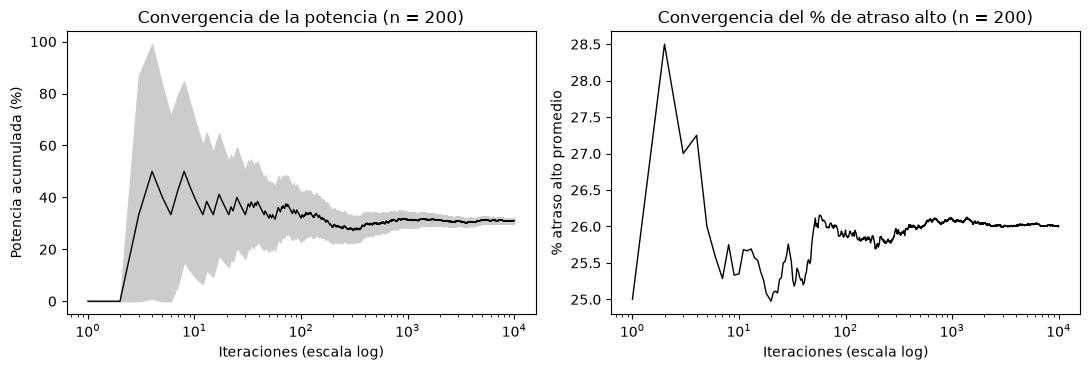

In [16]:
N_REF = 200
s = sims[N_REF]
k = np.arange(1, R + 1)
pot_acum = 100 * s["rechaza"].cumsum().to_numpy() / k
ee_mc = 100 * np.sqrt((pot_acum / 100) * (1 - pot_acum / 100) / k)
alto_acum = s["pct_alto"].cumsum().to_numpy() / k

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].plot(k, pot_acum, color="black", linewidth=1)
ejes[0].fill_between(k, np.clip(pot_acum - 1.96 * ee_mc, 0, None), pot_acum + 1.96 * ee_mc, color="0.8")
ejes[0].set_title(f"Convergencia de la potencia (n = {N_REF})")
ejes[0].set_ylabel("Potencia acumulada (%)")

ejes[1].plot(k, alto_acum, color="black", linewidth=1)
ejes[1].set_title(f"Convergencia del % de atraso alto (n = {N_REF})")
ejes[1].set_ylabel("% atraso alto promedio")

for ax in ejes:
    ax.set_xscale("log")
    ax.set_xlabel("Iteraciones (escala log)")
fig.tight_layout()
fig.savefig(RUTA_FIG / "fig_montecarlo_convergencia.png", dpi=300)
plt.show()

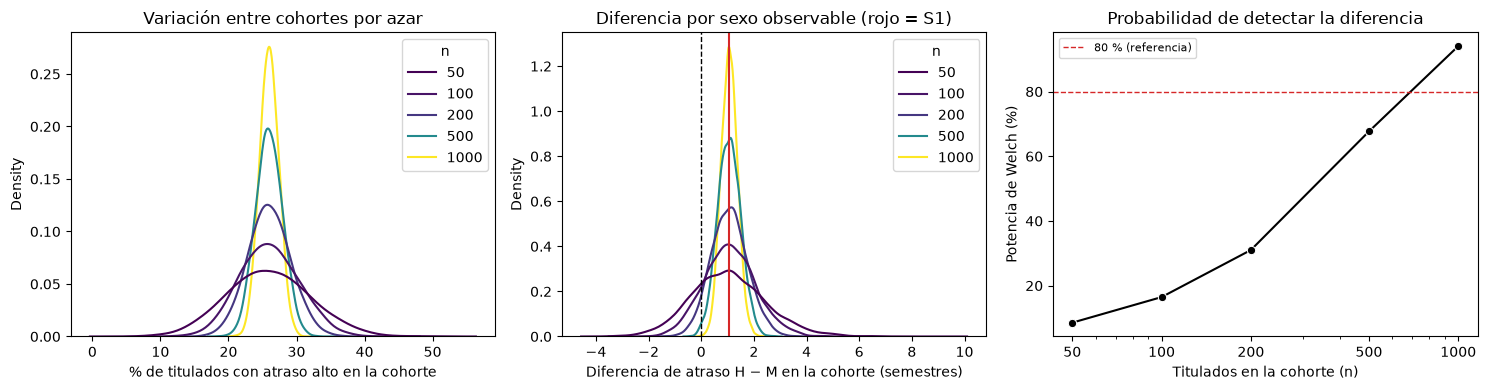

In [17]:
largo = pd.concat([sims[n].assign(n=n) for n in TAMANOS])

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

sns.kdeplot(data=largo, x="pct_alto", hue="n", common_norm=False, palette="viridis",
            bw_adjust=1.5, ax=ejes[0])
ejes[0].set_xlabel("% de titulados con atraso alto en la cohorte")
ejes[0].set_title("Variación entre cohortes por azar")

sns.kdeplot(data=largo, x="dif_HM", hue="n", common_norm=False, palette="viridis", ax=ejes[1])
ejes[1].axvline(0, color="black", linestyle="--", linewidth=1)
ejes[1].axvline(S1_WELCH["dif_medias"], color="tab:red", linewidth=1.5)
ejes[1].set_xlabel("Diferencia de atraso H − M en la cohorte (semestres)")
ejes[1].set_title("Diferencia por sexo observable (rojo = S1)")

potencia = largo.groupby("n")["rechaza"].mean() * 100
sns.lineplot(x=potencia.index, y=potencia.values, marker="o", color="black", ax=ejes[2])
ejes[2].axhline(80, color="tab:red", linestyle="--", linewidth=1, label="80 % (referencia)")
ejes[2].set_xscale("log")
ejes[2].set_xticks(TAMANOS, labels=TAMANOS)
ejes[2].set_xlabel("Titulados en la cohorte (n)")
ejes[2].set_ylabel("Potencia de Welch (%)")
ejes[2].set_title("Probabilidad de detectar la diferencia")
ejes[2].legend(fontsize=8)

fig.tight_layout()
fig.savefig(RUTA_FIG / "fig_montecarlo_resultados.png", dpi=300)
plt.show()

### Interpretación de la simulación Monte Carlo
**Coherencia con la S1.** Promediando las 10.000 cohortes, la simulación reproduce los parámetros de entrada: media de atraso 3,40 (S1: 3,398) y diferencia H−M 1,06–1,07 (S1: 1,068), para todos los tamaños. El % de atraso alto simulado (26,0 %) es 1,5 puntos mayor que el observado en el total (≈ 24,5 %, mezcla de 29,7 % en hombres y 20,5 % en mujeres): la binomial negativa reproduce media y varianza pero engrosa levemente la cola y no genera los atrasos negativos (1,4–2,0 % de los casos reales).

**Convergencia.** Las estimaciones acumuladas se estabilizan desde ≈ 1.000 iteraciones; con R = 10.000 el error Monte Carlo de la potencia es ≤ 0,5 puntos porcentuales, despreciable frente a las diferencias entre tamaños.

**Variabilidad entre cohortes.** Solo por azar, una carrera de 50 titulados puede mostrar entre 14 % y 38 % de atraso alto, y una de 200, entre 20 % y 32,5 %, aun cuando todas provienen del mismo sistema. Diferencias de ese orden entre carreras o años **no** deben interpretarse como cambios reales sin considerar el tamaño de la cohorte.

**Detectar la brecha por sexo.** La diferencia de 1,07 semestres es real a nivel nacional, pero pequeña (d = 0,23). En una cohorte de 200 titulados la prueba de Welch la detecta solo en el 31 % de los casos, y en el 5,9 % de las cohortes la diferencia observada sale invertida (mujeres más atrasadas). Se requieren cerca de 700 titulados para alcanzar 80 % de potencia (68 % con 500 y 94 % con 1.000), lo que concuerda con el cálculo analítico para d = 0,23 (≈ 620).

**Implicancia.** El hallazgo de la S1 es robusto a escala nacional, pero una institución que repita el análisis en su propia cohorte probablemente **no** encontrará diferencias significativas, y eso no contradice el resultado nacional: refleja falta de potencia, no ausencia de efecto. Para análisis institucionales se recomienda agrupar varias cohortes o reportar intervalos de confianza en vez de solo el valor *p*.